Analisis exploratorio de datos

Librerias

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

Carga de informacion

In [2]:
df = pd.read_csv("listings_clean.csv", parse_dates=["price_quote_checkin_date"])
print(f"Registros: {len(df):,}  |  Variables: {df.shape[1]}  |  Datos faltantes: {int(df.isna().sum().sum())}")
df.head(3)

Registros: 33,590  |  Variables: 64  |  Datos faltantes: 0


,id,price,log_price,island,neighbourhood,latitude,longitude,room_type,property_group,accommodates,...,am_dishwasher,am_tv,am_bbq,am_beach_waterfront,am_ocean_view,am_gym,am_elevator,am_self_checkin,am_workspace,am_patio_balcony
0,784020,848.33,6.743270,Maui,Lahaina,20.995184,-156.665009,Entire home/apt,House,8,...,1,1,1,1,0,0,0,1,1,1
1,461638,101.86,4.623599,Hawaii,South Hilo,19.721000,-155.084950,Private room,House,1,...,0,0,0,0,0,0,0,0,0,1
2,479121,265.00,5.579730,Hawaii,Puna,19.400310,-154.920430,Entire home/apt,House,6,...,0,1,1,1,1,0,0,0,0,1


creacion de caracteristicas de comparacion para el analisis
price_per_person: precio/capacidad
host_size:tamaño del operador
Rating:calificacion en bandas

In [3]:
df["price_per_person"] = df["price"] / df["accommodates"]
df["host_size"] = pd.cut(df["calculated_host_listings_count"], [0, 1, 5,50, np.inf],
labels=["1 anuncio", "2–5", "6–50", "más de 50"])
df["rating_band"] = pd.cut(df["review_scores_rating"], [0, 4.5, 4.7, 4.8, 4.9, 5.0],
labels=["< 4.5", "4.5–4.7", "4.7–4.8", "4.8–4.9", "4.9–5.0"], include_lowest=True)
amenidades = [c for c in df.columns if c.startswith("am_")]

Estadisticas descriptivas

In [5]:
numericas = ["price", "price_per_person", "accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights",
             "availability_365", "estimated_occupancy_l365d", "host_years", "calculated_host_listings_count",
             "number_of_reviews", "reviews_per_month", "review_scores_rating", "review_scores_value", "n_amenities"]
desc = df[numericas].describe(percentiles=[.25, .5, .75]).T
desc["asimetría"] = df[numericas].skew()
desc["curtosis"] = df[numericas].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
price,33590.0,495.15,377.42,67.72,257.12,375.50,594.00,2409.80,2.13,5.33
price_per_person,33590.0,106.95,64.88,7.16,64.58,91.00,130.67,1615.00,2.79,21.93
accommodates,33590.0,4.79,2.32,1.00,4.00,4.00,6.00,16.00,1.49,3.99
bedrooms,33590.0,1.54,1.02,0.00,1.00,1.00,2.00,5.00,0.79,0.90
beds,33590.0,2.61,1.40,1.00,2.00,2.00,3.00,8.00,1.26,2.12
bathrooms,33590.0,1.60,0.77,0.00,1.00,1.00,2.00,4.50,1.28,1.74
minimum_nights,33590.0,5.80,19.22,1.00,1.00,2.00,3.00,365.00,9.26,107.04
availability_365,33590.0,233.74,97.17,0.00,175.00,256.00,309.00,365.00,-0.72,-0.41
estimated_occupancy_l365d,33590.0,55.46,73.75,0.00,0.00,18.00,90.00,255.00,1.37,0.79
host_years,33590.0,6.91,3.86,0.00,3.92,6.92,10.17,15.67,0.03,-0.97


composicion

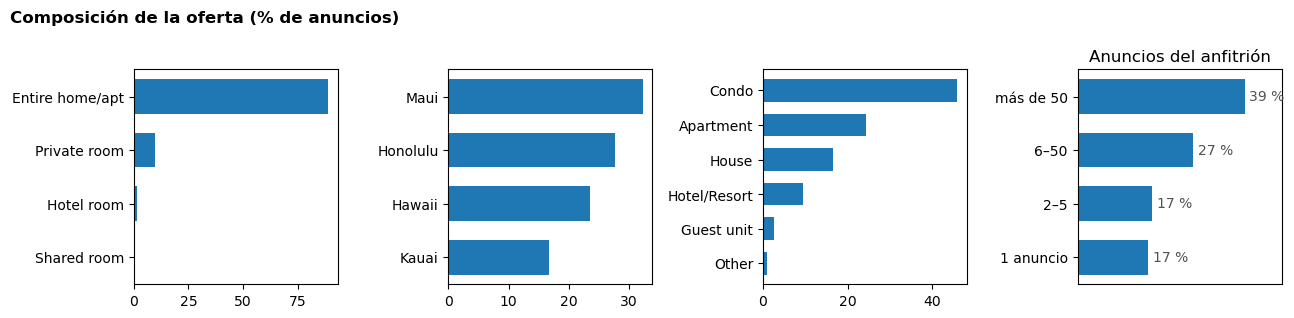

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (c, titulo) in zip(axes, [("room_type", "Tipo de alojamiento"), ("island", "Isla"),("property_group", "Tipo de edificación"), ("host_size", "Anuncios del anfitrión")]):
    vc = (df[c].value_counts(normalize=True) * 100).sort_values()
    ax.barh(vc.index.astype(str), vc.values, height=0.65)
for y, v in enumerate(vc.values):
    ax.text(v + 1, y, f"{v:.0f} %", va="center", color="#52514e")
ax.set_title(titulo); ax.set_xlim(0, vc.max() * 1.22); ax.grid(False); ax.set_xticks([])
plt.suptitle("Composición de la oferta (% de anuncios)", x=0.01 ,ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

el 89% de los alojaminetos son completos, casio la mitad son condominios luegos aptos y casas.

el 39% pertenece a administradores de propiedades vs 17% a personas con un solo anuncio


Variable objetivo precio por noche

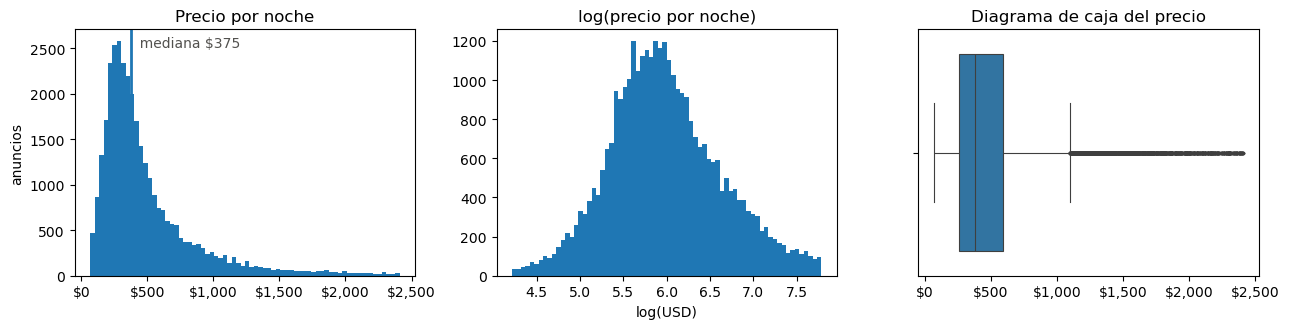

Media $495 | Mediana $375 | Rango intercuartílico $257–$594 | Asimetría precio 2.13 vs. log(precio) 0.28


In [20]:
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(df["price"], bins=70)
axes[0].axvline(df["price"].median(), lw=2)
axes[0].text(df["price"].median(), axes[0].get_ylim()[1] * 0.93, f"  mediana ${df['price'].median():,.0f}", color="#52514e")
axes[0].set_title("Precio por noche"); axes[0].xaxis.set_major_formatter(usd); axes[0].set_ylabel("anuncios")
axes[1].hist(df["log_price"], bins=70)
axes[1].set_title("log(precio por noche)"); axes[1].set_xlabel("log(USD)")
sns.boxplot(x=df["price"], ax=axes[2], fliersize=1.5, linewidth=0.8)
axes[2].set_title("Diagrama de caja del precio"); axes[2].xaxis.set_major_formatter(usd); axes[2].set_xlabel("")
plt.tight_layout()
plt.show()
print(f"Media ${df['price'].mean():,.0f} | Mediana ${df['price'].median():,.0f} | "
      f"Rango intercuartílico ${df['price'].quantile(.25):,.0f}–${df['price'].quantile(.75):,.0f} | "
      f"Asimetría precio {df['price'].skew():.2f} vs. log(precio) {df['log_price'].skew():.2f}")


el precio mediano por noche es de 375 USD por noche y la mitad de los anuncios esta en 257 - 594 la media 495 usd  

tien cola pesada a la derecha aplicamos logaritmo  y ya parece una normal

por lo que ahora nuetra variable es log (precios)


precio y ubicacion

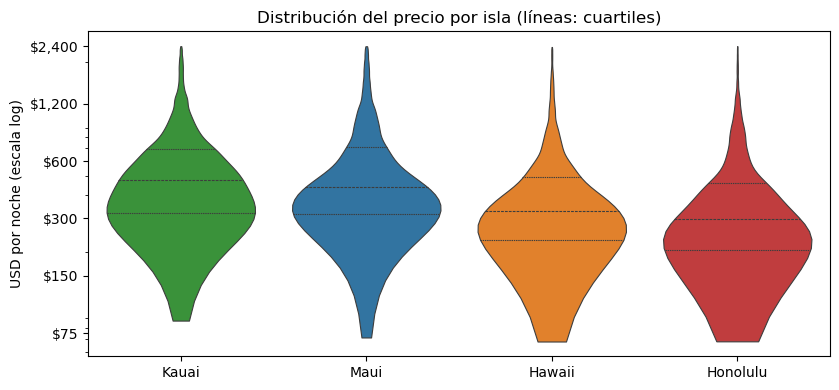

,count,25%,50%,75%
island,,,,
Kauai,5586.0,320.0,475.0,693.0
Maui,10830.0,315.0,437.0,709.0
Hawaii,7907.0,230.0,328.0,493.0
Honolulu,9267.0,204.0,297.0,463.0


In [ ]:
orden_islas = df.groupby("island")["price"].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 4))
sns.violinplot(data=df, x="island", y="price", hue="island", order=orden_islas,inner="quartile", cut=0, linewidth=0.8, legend=False, ax=ax)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set_yticks([75, 150, 300, 600, 1200, 2400])
ax.set_xlabel(""); ax.set_ylabel("USD por noche (escala log)")
ax.set_title("Distribución del precio por isla (líneas: cuartiles)")
plt.tight_layout()
plt.show()
df.groupby("island")["price"].describe()[["count", "25%", "50%", "75%"]].loc[orden_islas].round(0)

precio por zona

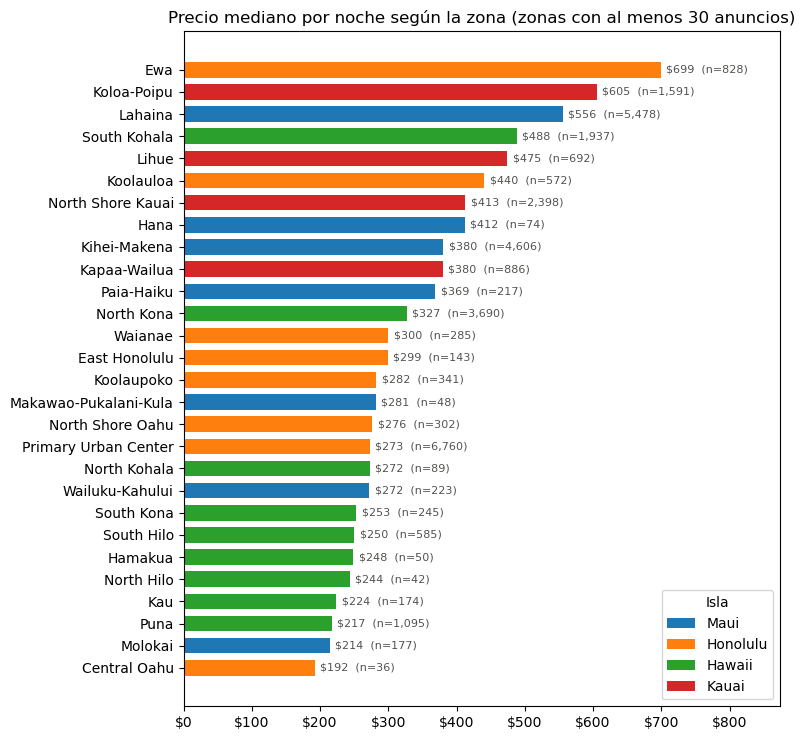

In [35]:
from matplotlib.patches import Patch

colores = {
    "Maui": "#1f77b4",
    "Honolulu": "#ff7f0e",
    "Hawaii": "#2ca02c",
    "Kauai": "#d62728",
}

zonas = df.groupby(["neighbourhood", "island"])["price"].agg(mediana="median", anuncios="size").reset_index()
zonas = zonas[zonas["anuncios"] >= 30].sort_values("mediana")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(zonas["neighbourhood"], zonas["mediana"],color=zonas["island"].map(colores), height=0.7)
for y, (v, n) in enumerate(zip(zonas["mediana"], zonas["anuncios"])):
    ax.text(v + 8, y, f"${v:,.0f}  (n={n:,})", va="center", color="#52514e", fontsize=8)
ax.xaxis.set_major_formatter(usd); ax.set_xlim(0, zonas["mediana"].max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_title("Precio mediano por noche según la zona (zonas con al menos 30 anuncios)")
ax.legend(handles=[Patch(facecolor=c, label=isla) for isla, c in colores.items()], title="Isla", loc="lower right")
plt.tight_layout()
plt.show()